In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##### For EDA Upload Cleaned Tables

In [66]:
shipment = pd.read_csv("cleaned_Shipment.csv")
business = pd.read_csv("cleaned_Business_Metrics.csv")
external = pd.read_csv("cleaned_External_Factors.csv")
status = pd.read_csv("cleaned_Status.csv")
supplier = pd.read_csv("cleaned_Supplier.csv")
transport = pd.read_csv("cleaned_Transportation.csv")
warehouse = pd.read_csv("cleaned_Warehouse.csv")

##### By using shape checked total rows and columns of tables after uploading tables.

In [108]:
print(shipment.shape)
print(business.shape)
print(external.shape)
print(status.shape)
print(supplier.shape)
print(transport.shape)
print(warehouse.shape)

(60000, 8)
(60000, 4)
(60000, 5)
(60000, 2)
(100, 4)
(60000, 4)
(30, 3)


#### 1. Total Shipment

##### Table- Shipment

In [68]:
shipment.head()

,Shipment_ID,Order_ID,Shipment_Date,Delivery_Date,Delivery_Time,Supplier_ID,Warehouse_ID
0,SHP000001,ORD000001,2024-08-18,2024-08-22,07:19:57,SUP0013,WH001
1,SHP000002,ORD000002,2024-07-08,2024-07-13,14:10:01,SUP0036,WH013
2,SHP000003,ORD000003,2024-08-12,2024-08-22,01:12:56,SUP0081,WH016
3,SHP000004,ORD000004,2025-01-19,2025-01-22,05:49:42,SUP0076,WH023
4,SHP000005,ORD000005,2025-01-11,2025-01-19,18:58:14,SUP0042,WH005


In [106]:
Total_shipments = shipment["Shipment_ID"].nunique()

In [107]:
Total_shipments 

60000

##### nunique()- counts unique shipment IDs.
##### Here counted the unique Shipment IDs in the Shipment table. There are 60,000 total shipments in the dataset.

#### 2.Delayed shipments 

##### Table- Business Metrics

In [109]:
business = pd.read_csv("delay_hours_update.csv")

business["Delay_Hours"].describe()

count    60000.000000
mean         4.213851
std          4.503244
min          0.000000
25%          0.000000
50%          3.200000
75%          6.590000
max         38.340000
Name: Delay_Hours, dtype: float64

In [110]:
Delayed_shipments = (business["Delay_Hours"] > 0).sum()
print("Delayed Shipments:", Delayed_shipments)

Delayed Shipments: 42007


##### Here used the Delay Hours column. If Delay_Hours is greater than zero,it classify the shipment as delayed.
##### There are total 42007 delayed shipments.

#### 3.Delay rate

##### Formula used = Delay Rate = Delayed Shipments / Total Shipments × 100

In [72]:
business = pd.read_csv("delay_hours_update.csv")

business["Delay_Hours"].describe()

count    60000.000000
mean         4.213851
std          4.503244
min          0.000000
25%          0.000000
50%          3.200000
75%          6.590000
max         38.340000
Name: Delay_Hours, dtype: float64

In [73]:
Delayed_shipments = (business["Delay_Hours"] > 0).sum()
Total_shipments = business["Shipment_ID"].nunique()

Delay_rate = (Delayed_shipments / Total_shipments) * 100

print("Delay Rate:", Delay_rate, "%")

Delay Rate: 70.01166666666667 %


##### Delay rate shows the percentage of shipments that were delayed.
##### so,divided delayed shipments by total shipments and multiplied by 100.
##### so that the delay rate is 70%.

#### 4.Average delay hours 

##### Table- Business Metrics

In [74]:
average_delay = business["Delay_Hours"].mean()

print("Average Delay Hours:", average_delay)

Average Delay Hours: 4.213850833333333


##### mean() - Used for calculating average delay.

#### 5.Shipment trend 

##### How many shipments were made in each month?

##### Covert the date 

In [75]:
shipment["Shipment_Date"] = pd.to_datetime( shipment["Shipment_Date"])

##### Create Month-converted Shipment Date into monthly periods and counted unique shipments for each month. 

In [76]:
shipment["Month"] = shipment["Shipment_Date"].dt.month

##### Count Shipments

In [77]:
monthly_shipments = shipment.groupby("Month")["Shipment_ID"].nunique()
print(monthly_shipments)

Month
1     5822
2     5044
3     5746
4     5560
5     5692
6     5647
7     5818
8     5863
9     3695
10    3803
11    3610
12    3700
Name: Shipment_ID, dtype: int64


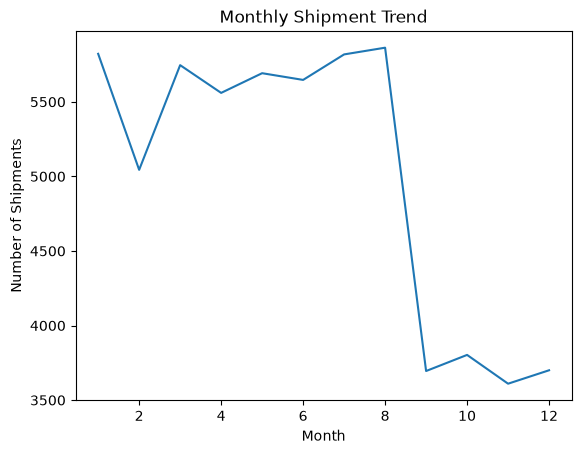

In [78]:
monthly_shipments.plot(
    kind="line",
      title="Monthly Shipment Trend",
    xlabel="Month",
    ylabel="Number of Shipments")

plt.show()

##### This line plot shows how the number of shipments changes month by month(Shipment Trend by month).
##### Shipment volume was relatively high from January to August, with some fluctuations. 
##### There was a significant drop in shipments in September.
##### From September to December, the number of shipments remained lower and relatively stable.
##### This helps to understand the shipments volume trend over time.

#### 6.Supplier performance

##### Table- shipment, business metrics, and supplier.

In [79]:
Supplier = shipment.merge(business, on="Shipment_ID")

In [80]:
Supplier = Supplier.merge(supplier, on="Supplier_ID")

In [81]:
Supplier_performance = Supplier.groupby("Supplier_Name")["Delay_Hours"].mean()

print(Supplier_performance.sort_values())

Supplier_Name
Kala-Rattan                      3.794113
Roy-Sibal                        3.839473
Randhawa-Deep                    3.843523
Dewan-Koshy                      3.892688
Mangal-Sampath                   3.896394
                                   ...   
Murthy and Sons                  4.512983
Iyer, Muni and Rastogi           4.558322
Choudhury, Bakshi and Maharaj    4.580048
Palla Inc                        4.647096
Pant-Kadakia                     4.724828
Name: Delay_Hours, Length: 100, dtype: float64


In [82]:
Supplier_performance.head(10)

Supplier_Name
Ahuja-Dutta                   4.220530
Amble Inc                     4.037594
Andra Group                   4.104974
Apte-Contractor               4.066057
Bala, Issac and Saini         4.422460
Balan Inc                     4.327093
Baral, Bumb and Saini         4.202144
Batta Inc                     4.245570
Bhagat, Chaudhari and Bhat    3.911601
Bhargava, Karnik and Bir      4.299116
Name: Delay_Hours, dtype: float64

In [83]:
Supplier_performance.nunique()

100

##### Analyzed supplier performance using average Delay_Hours for each supplier.
##### Used merge()function to merge common column(Shipment_ID) of supplier, business metrics and shipment table. 

#### 7.Route performance

##### Table - Transportation,Business Metrics

In [84]:
route_data = transport.merge(business,on="Shipment_ID")

In [85]:
route_performance = route_data.groupby( "Route_Distance")["Delay_Hours"].mean()
print(route_performance)

Route_Distance
20.05       0.00
20.06       0.00
20.08       4.00
20.09       0.00
20.13       2.62
           ...  
2499.69     3.52
2499.76     4.16
2499.85     2.57
2499.89     0.50
2499.93    10.15
Name: Delay_Hours, Length: 53363, dtype: float64


In [86]:
route_performance.head(10)

Route_Distance
20.05     0.00
20.06     0.00
20.08     4.00
20.09     0.00
20.13     2.62
20.14     6.03
20.18     2.84
20.19    10.91
20.24     1.44
20.30     4.01
Name: Delay_Hours, dtype: float64

##### For Route Performance, grouped the data by Route Distance and calculated the average Delay Hours for each route distance.

#### 8.Delay by transport mode

##### Table- Transportation and Business metrics

##### Question - Which transport mode has the highest average delay?

##### Trasnportation table contains four transport Mode - Road, Air, Sea, Rail.

In [87]:
transport_mode_data = transport.merge(business, on="Shipment_ID")

In [88]:
Transport_delay = transport_mode_data.groupby("Transport_Mode")["Delay_Hours"].mean()
print(Transport_delay)

Transport_Mode
Air     4.162074
Rail    4.195871
Road    4.230032
Sea     4.239343
Name: Delay_Hours, dtype: float64


##### grouped the shipments by Transport Mode and calculated the average Delay Hours for each transport mode.

##### Bar Graph

<Axes: title={'center': 'Average Delay by Transport Mode'}, xlabel='Transport_Mode', ylabel='Average Delay Hours'>

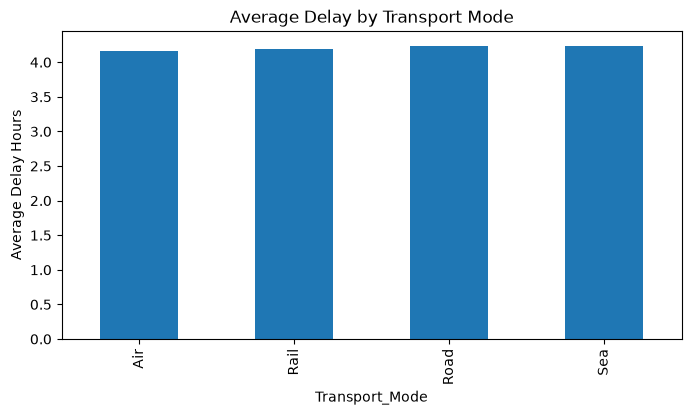

In [111]:
Transport_delay.plot(
    kind="bar",
    figsize=(8, 4),
    title="Average Delay by Transport Mode",
    ylabel="Average Delay Hours")

#### 9.Weather versus delay

##### Table - External Factors and Business Metrics

##### External factors table contains weather condition column - Weather Conditions are - Clear, Rain, Storm, Cloudy, Fog  

In [90]:
Weather_data = external.merge(business,on="Shipment_ID")

In [91]:
Weather_delay = Weather_data.groupby("Weather_Condition")["Delay_Hours"].mean()

print(Weather_delay)

Weather_Condition
Clear         4.209560
Cloudy        4.297705
Fog           4.098032
Heavy Rain    4.210104
Rain          4.205595
Storm         4.133850
Name: Delay_Hours, dtype: float64


##### grouped the shipments according to weather condition and calculated the average delay hours for each condition. 
##### This helps to understand the relationship between weather conditions and shipment delays.

#### 10.Traffic versus delay

##### Table - External Factor and Business Metrics

In [92]:
traffic = external.merge(business,on="Shipment_ID")
Traffic_delay = traffic.groupby("Traffic_Level")["Delay_Hours"].mean()

print(Traffic_delay)

Traffic_Level
High      4.254604
Low       4.183755
Medium    4.200189
Severe    4.240417
Name: Delay_Hours, dtype: float64


##### Bar Graph

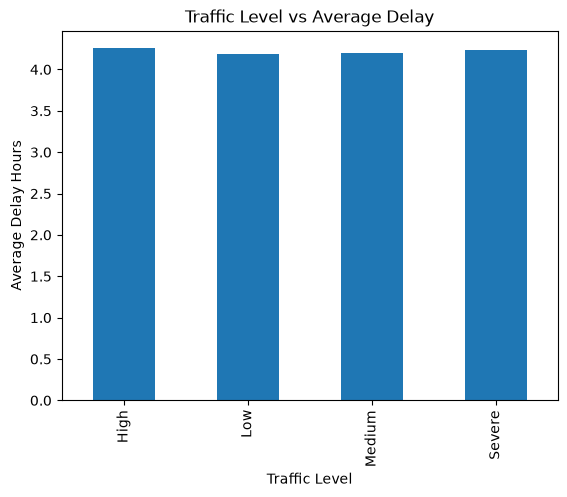

In [93]:
Traffic_delay.plot(
    kind="bar",
    title="Traffic Level vs Average Delay",
    xlabel="Traffic Level",
    ylabel="Average Delay Hours")
plt.show()

#### 11.Port congestion versus delay

##### Table - External Factors and Business Metrics

##### External Factors table contains Port congestion column in that - Low, Medium, High Congestion

In [94]:
port_congestion_data = external.merge(business,on="Shipment_ID")

In [95]:
port_delay = port_congestion_data.groupby("Port_Congestion")["Delay_Hours"].mean()

print(port_delay)

Port_Congestion
High      4.240191
Low       4.198881
Medium    4.224179
Name: Delay_Hours, dtype: float64


##### Bar Graph

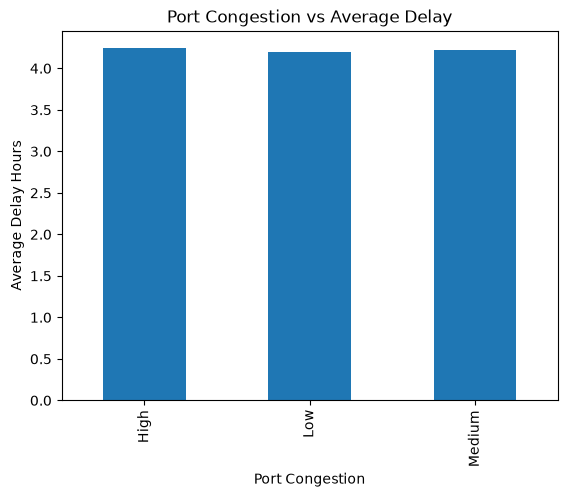

In [96]:
port_delay.plot(
    kind="bar",
    title="Port Congestion vs Average Delay",
    xlabel="Port Congestion",
    ylabel="Average Delay Hours")

plt.show()

#### 12.Delivery cost analysis

##### Find the total delivery cost

In [102]:
business = pd.read_csv("cleaned_Business_Metrics.csv")

business.columns = business.columns.str.strip()

In [103]:
business

,Shipment_ID,Delivery_Cost,Delay_Hours,Customer_Priority
0,SHP000001,1526.84,1.86,Medium
1,SHP000002,6124.35,17.67,Medium
2,SHP000003,5606.66,5.44,Medium
3,SHP000004,2200.06,14.29,Medium
4,SHP000005,3826.46,1.56,High
...,...,...,...,...
59995,SHP059996,1198.71,2.22,Critical
59996,SHP059997,3862.61,12.32,Low
59997,SHP059998,10028.56,4.97,Medium
59998,SHP059999,4164.05,6.55,High


In [104]:
total_delivery_cost = business["Delivery_Cost"].sum()

print("Total Delivery Cost:", total_delivery_cost)

Total Delivery Cost: 312712469.6


##### Find the average delivery cost

In [ ]:
Average_delivery_cost = business["Delivery_Cost"].mean()
print("Average Delivery Cost:",Average_delivery_cost) 

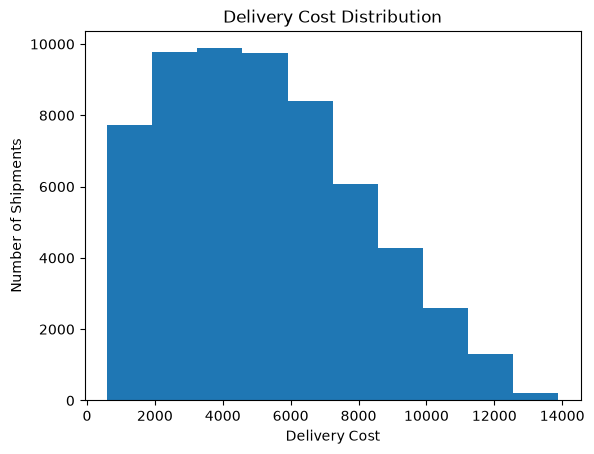

In [105]:
business["Delivery_Cost"].plot(
    kind="hist",
    bins=10,
    title="Delivery Cost Distribution",
    xlabel="Delivery Cost",
    ylabel="Number of Shipments")

plt.show()

##### Delivery Cost Analysis, Used a histogram to understand the distribution of delivery costs across shipments. 
##### The X-axis shows delivery cost ranges and the Y-axis shows the number of shipments in each range.
##### From the graph, I can see that most shipments have delivery costs between approximately 2,000 and 6,000.
##### As the delivery cost increases, the number of shipments decreases.
##### Only a small number of shipments have very high delivery costs.